# Analyse ROMY Event - Demo 1

## Notebook Overview
This notebook performs event-wise ROMY processing, including backazimuth and dispersion analysis with diagnostic plotting.

**Main workflow**
- Load event configuration and waveform streams.
- Preprocess traces (trim, filter, polarity/time-cut handling).
- Compute backazimuth and wavefield metrics.
- Estimate dispersion/velocity curves.
- Create and save event-level summary figures.

ROMY data of an M6.8 event in 2023 is analyzed loading data from a local MSEED file.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from obspy import UTCDateTime
from sixdegrees.sixdegrees import sixdegrees

from sixdegrees.plots.plot_waveform_cc import plot_waveform_cc
from sixdegrees.plots.plot_cwt_all import plot_cwt_all
from sixdegrees.plots.plot_velocities import plot_velocities
from sixdegrees.plots.plot_backazimuth_results import plot_backazimuth_results
from sixdegrees.plots.plot_spectra_comparison_fill import plot_spectra_comparison_fill
from sixdegrees.plots.plot_backazimuth_map import plot_backazimuth_map
from sixdegrees.plots.plot_dispersion_curves import plot_dispersion_curves
from sixdegrees.plots.plot_dispersion_traces import plot_dispersion_traces

## Configurations

In [2]:
# date = '20190514'

date = '20230908'
# date = '20230912'
# date = '20231202'
# date = '20231203' # no data

# date = '20240314'
# date = '20240322'
# date = '20240323'
# date = '20240414'
# date = '20240422'
# date = '20240815'
# date = '20241023'
# date = '20240915'

# date = '20250602'
# date = '20250513'
# date = '20251206'
# date = '20251212'
# date = '20251227'

# date = '20260107'
# date = '20260420'



# set if figures are saved
save_figures = True


Load the configuration for the event

In [3]:
config = sixdegrees.load_from_yaml(f"./events/event_{date}/config_romy_{date}.yml")

In [4]:
# check if path to figures exists
if save_figures and not os.path.exists(config['path_to_figures']):
    os.makedirs(config['path_to_figures'])


Setup a sixdegrees object

In [5]:
sd = sixdegrees(conf=config)

Get key information about the event

In [6]:
ev = sd.get_event_info(
    origin_time=config['origin_time'],
    base_catalog="USGS",
    magnitude=config['magnitude']
)

Found event:
Origin time: 2023-09-08T22:11:01.405000Z
Magnitude: 6.8 mww
Location: 31.058°N, -8.385°E
Depth: 19.0 km
Epicentral Distance: 2526.01 km
Epicentral Distance: 22.7°
Backazimuth: 228.40°


Let's load the data based on the configuration file. We also apply a resampling.

In [7]:
sd.load_data(config['tbeg'], config['tend'], resample_rate=5)

-> fetching XX.ROMY..BHZ data from mseed file
-> fetching XX.ROMY..BHN data from mseed file
-> fetching XX.ROMY..BHE data from mseed file
3 Trace(s) in Stream:
XX.ROMY..BHZ | 2023-09-08T22:14:28.990000Z - 2023-09-08T22:43:00.990000Z | 20.0 Hz, 34241 samples
XX.ROMY..BHN | 2023-09-08T22:14:28.990000Z - 2023-09-08T22:43:00.990000Z | 20.0 Hz, 34241 samples
XX.ROMY..BHE | 2023-09-08T22:14:28.990000Z - 2023-09-08T22:43:00.990000Z | 20.0 Hz, 34241 samples
-> fetching XX.ROMY..BJZ data from mseed file
-> fetching XX.ROMY..BJN data from mseed file
-> fetching XX.ROMY..BJE data from mseed file
3 Trace(s) in Stream:
XX.ROMY..BJZ | 2023-09-08T22:14:29.011600Z - 2023-09-08T22:43:01.011600Z | 20.0 Hz, 34241 samples
XX.ROMY..BJN | 2023-09-08T22:14:28.999399Z - 2023-09-08T22:43:00.999399Z | 20.0 Hz, 34241 samples
XX.ROMY..BJE | 2023-09-08T22:14:28.986601Z - 2023-09-08T22:43:00.986601Z | 20.0 Hz, 34241 samples
-> resampling stream to 5 Hz
6 Trace(s) in Stream:
XX.ROMY..LHZ | 2023-09-08T22:14:28.990000

Ensure that all traces of stream have the same sample size

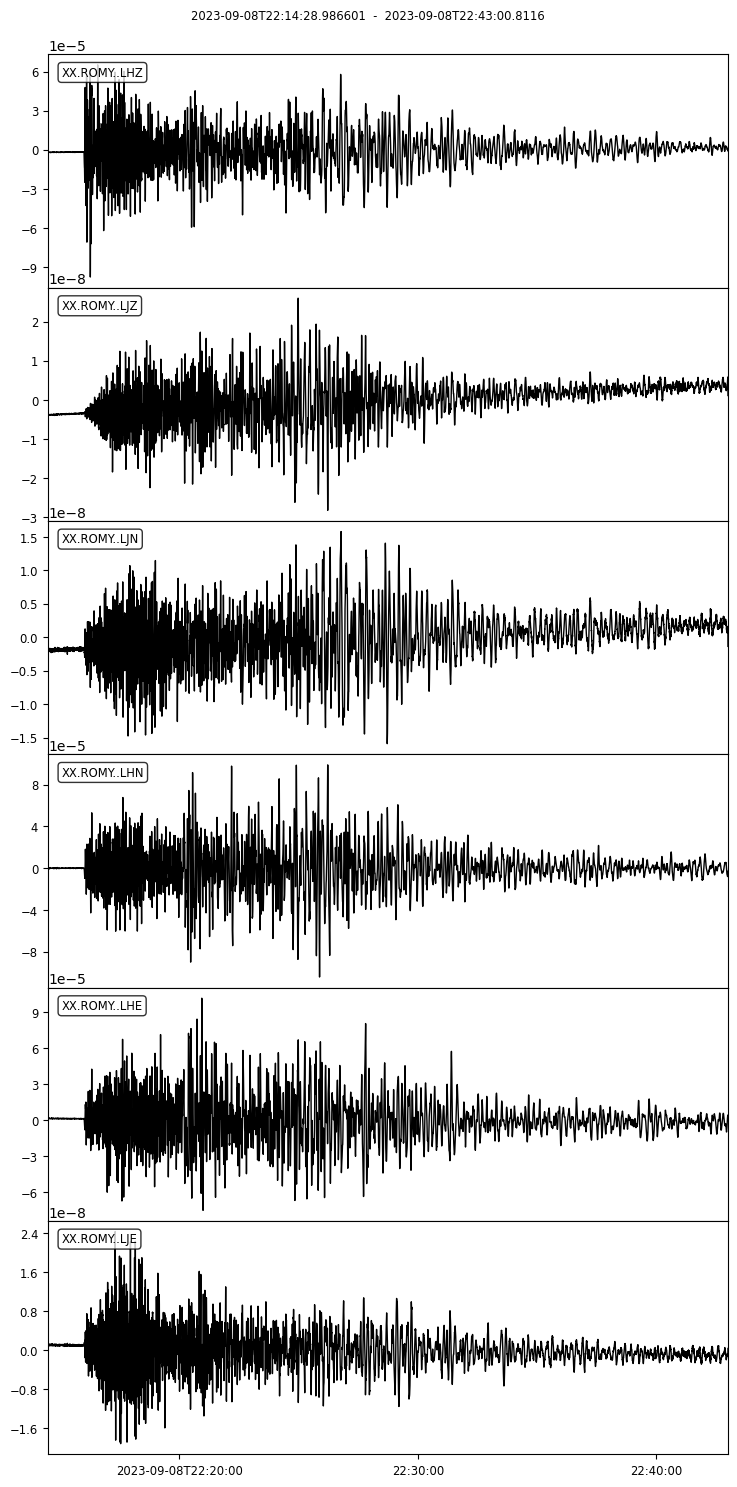

In [8]:
sd.st.plot(equal_scale=False);

Ensure alls traces have the same amount of samples

In [9]:
sd.trim_stream(set_common=True, set_interpolate=True)

 -> trim_stream: window 2023-09-08T22:14:29.011600Z -> 2023-09-08T22:43:00.786601Z
    initial npts=[8560, 8560, 8560, 8560, 8560, 8560], rates=[5.0]
    linear interpolation -> 5.0 Hz, anchored at 2023-09-08T22:14:29.011600Z
    final: starttimes={'2023-09-08T22:14:29.011600Z'}, npts={8559}, rates={5.0}


## Analysis

In [10]:
sd.correct_tilt()

Frequency band to filter (this is applied to the stream object after being reset to raw stream)

In [11]:
sd.filter_data(fmin=config['fmin'], fmax=config['fmax'], output=False)

Apply polarity correction if needed. This is applied to the stream object that is processed. If raw is True, the polarity correction is applied to the raw stream too.

In [12]:
sd.polarity_stream(pol_dict={"HZ": -1, "JZ": 1}, raw=True)

-> polarity for channel HZ changed from 1 to -1


Cut bad data if specified in config file

In [13]:
if 'time_cuts' in config:
    for key, values in config['time_cuts'].items():
        for value in values:
            sd.replace_values_in_window(tbeg=value[0], tend=value[1], value=0, channel_list=[key])

Now, let's compare the waveforms of the rotation (red) and translational (black) components 

In [14]:
# get travel times for P and S waves
P_travel_time = UTCDateTime(sd.get_theoretical_arrival(phase="P")) - UTCDateTime(config['tbeg']) - 10
S_travel_time = UTCDateTime(sd.get_theoretical_arrival(phase="S")) - UTCDateTime(config['tbeg']) - 10


Theoretical P-arrival: 2023-09-08T22:16:02.016641Z


Theoretical S-arrival: 2023-09-08T22:20:10.994445Z


Theoretical P-arrival: 2023-09-08T22:16:02.016641Z
Theoretical S-arrival: 2023-09-08T22:20:10.994445Z


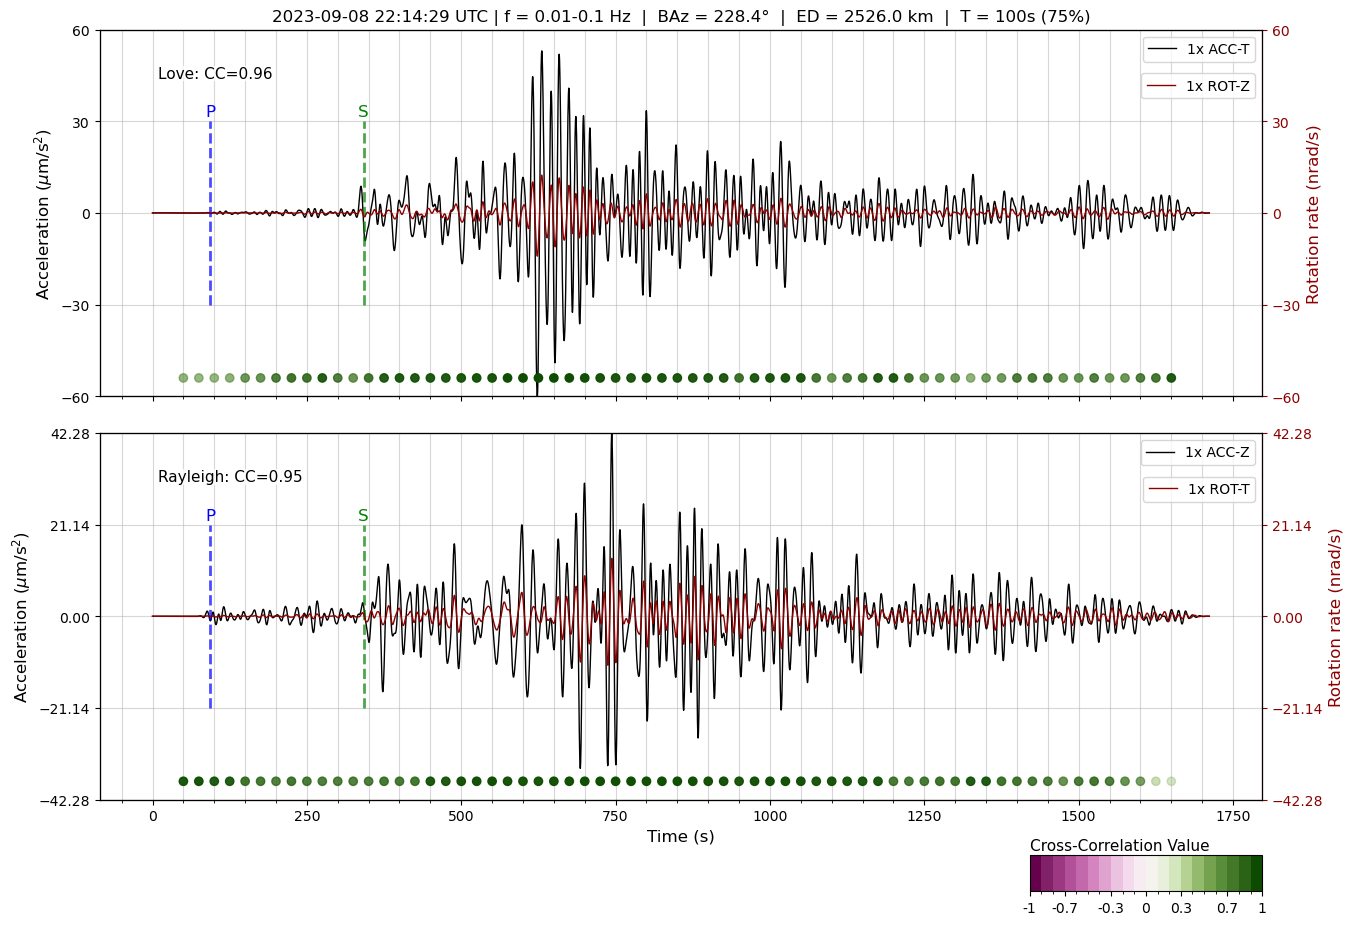

In [15]:
fig = plot_waveform_cc(
    sd_object=sd,
    twin_sec=config['twin_sec'],
    twin_overlap=config['twin_overlap'],
    wave_type="both",
    scaled=True,
    show_p_arrival=True,
    show_s_arrival=True,
)

# add vertical lines for P and S waves
# fig.axes[0].plot([P_travel_time, P_travel_time], [-5, 5], color="tab:green", ls="--")
# fig.axes[0].plot([S_travel_time, S_travel_time], [-5, 5], color="tab:blue", ls="--")
# fig.axes[1].plot([P_travel_time, P_travel_time], [-5, 5], color="tab:green", ls="--")
# fig.axes[1].plot([S_travel_time, S_travel_time], [-5, 5], color="tab:blue", ls="--")

# # add text P and S 
# fig.axes[0].text(P_travel_time, 5, "P", color="tab:green", ha="center", va="bottom", fontsize=12)
# fig.axes[0].text(S_travel_time, 5, "S", color="tab:blue", ha="center", va="bottom", fontsize=12)
# fig.axes[1].text(P_travel_time, 5, "P", color="tab:green", ha="center", va="bottom", fontsize=12)
# fig.axes[1].text(S_travel_time, 5, "S", color="tab:blue", ha="center", va="bottom", fontsize=12)

if save_figures:
    fig.savefig(f"{config['path_to_figures']}{date}_waveform_cc.png", dpi=150, bbox_inches='tight')

In [16]:
# UTCDateTime(config['tbeg'])+1250

Add time cuts with bad data to config file

In [17]:
# from obspy import UTCDateTime

# time_cuts = {
#     "JN": [('2025-12-12T03:30:00.000000Z', '2025-12-12T03:32:30.000000Z')],
#     "JE": [('2025-12-12T03:30:00.000000Z', '2025-12-12T03:32:30.000000Z')],
#     }
# if 'time_cuts' not in config:
#     config['time_cuts'] = time_cuts
# else:
#     config['time_cuts'] = {**config['time_cuts'], **time_cuts}

# # get date
# date = config['origin_time'][:10].replace('-', '')

# # define filename
# filename = f"./events/event_{date}/config_romy_{date}.yml"

# os.remove(filename)

# # store the configuration as a yaml file
# sd.store_as_yaml(config, filename)

In [18]:
# from obspy import UTCDateTime

# time_cuts = {
#     "JN": [(str(UTCDateTime(config['tbeg'])+4000), str(UTCDateTime(config['tbeg'])+4200)),
#           (str(UTCDateTime(config['tbeg'])+1000), str(UTCDateTime(config['tbeg'])+1300))],
#     "JE": [(str(UTCDateTime(config['tbeg'])+4000), str(UTCDateTime(config['tbeg'])+4200)),
#           (str(UTCDateTime(config['tbeg'])+1000), str(UTCDateTime(config['tbeg'])+1300))],
#     }
# if 'time_cuts' not in config:
#     config['time_cuts'] = time_cuts
# else:
#     config['time_cuts'] = {**config['time_cuts'], **time_cuts}

# # get date
# date = config['origin_time'][:10].replace('-', '')

# # define filename
# filename = f"./events/event_{date}/config_romy_{date}.yml"

# os.remove(filename)

# # store the configuration as a yaml file
# sd.store_as_yaml(config, filename)

Make spectra for the raw data

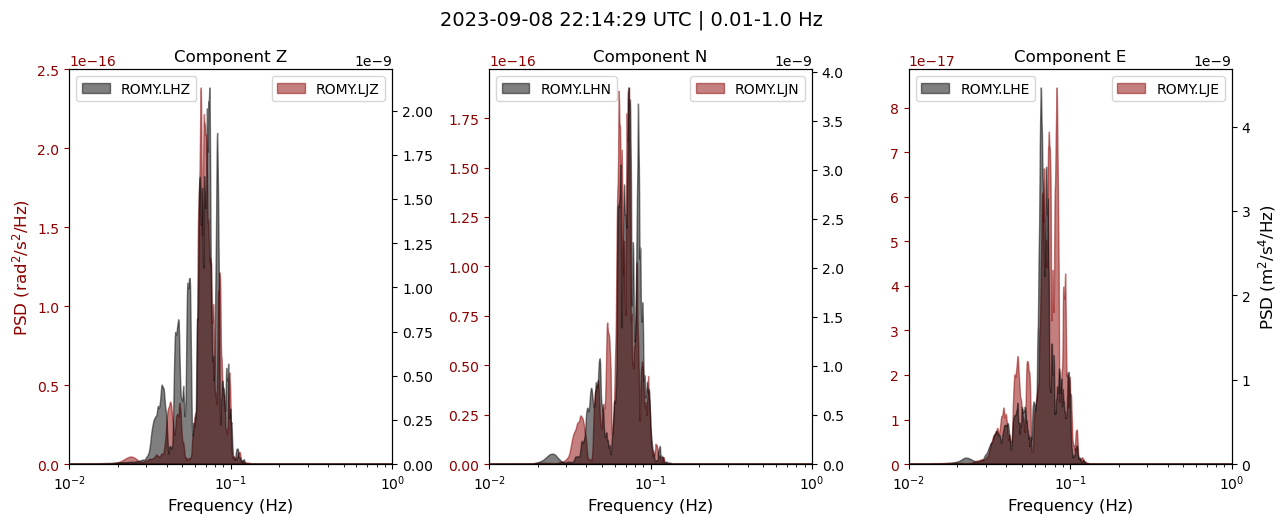

In [19]:
# Plot the spectra comparison
fig = plot_spectra_comparison_fill(
    sd_object=sd,
    fmin=0.01,
    fmax=1.0,
    ylog=False,
    xlog=True,
    fill=True # fill spectra
)

if save_figures:
    fig.savefig(f"{config['path_to_figures']}{date}_spectra_comparison.png")

### Backazimuth Estimate

Computation of backazimuth results for Love waves using the midpoint CC-method

baz_max = 237, baz_std = 19


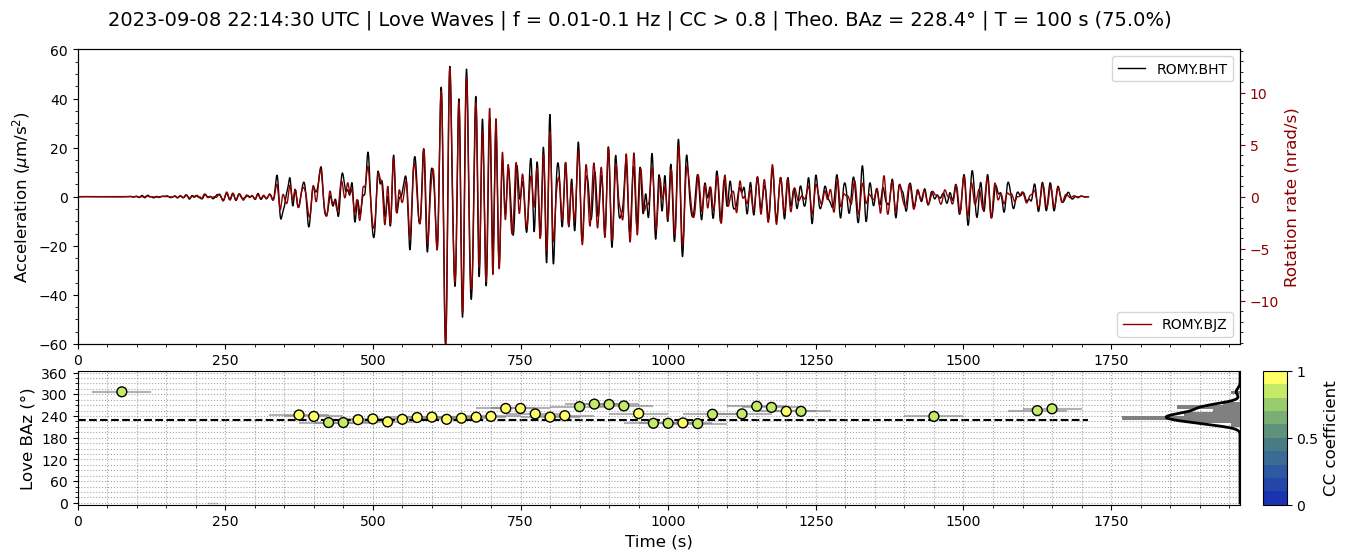

In [20]:
# First compute backazimuth
baz_results_love = sd.compute_backazimuth(
    wave_type='love',
    baz_step=config['baz_step'],
    baz_win_sec=config['twin_sec'],
    baz_win_overlap=config['twin_overlap'],
    out=True
)

# Then plot results
fig = plot_backazimuth_results(
    sd,
    baz_results_love,
    wave_type='love',
    cc_method='mid',
    baz_theo=ev['backazimuth'],
    cc_threshold=config['cc_threshold'],
)
if save_figures:
    fig.savefig(f"{config['path_to_figures']}{date}_backazimuth_love_mid.png")

Computation of backazimuth results for Rayleigh waves using the midpoint CC-method

baz_max = 231, baz_std = 10


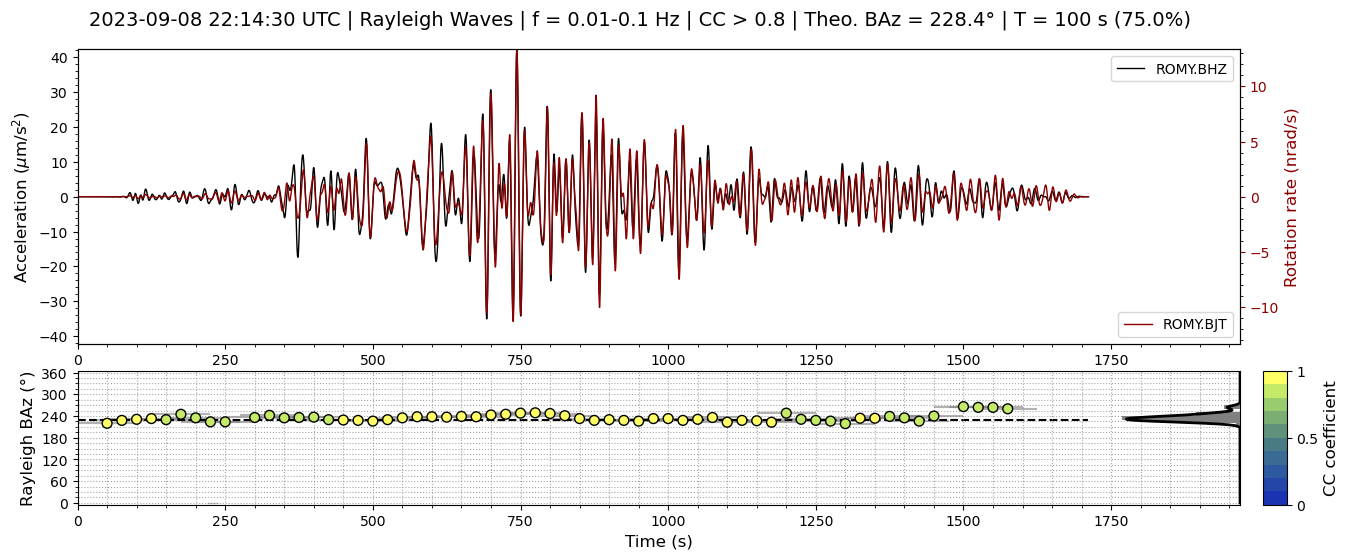

In [21]:
# First compute backazimuth
baz_results_rayleigh = sd.compute_backazimuth(
    wave_type='rayleigh',
    baz_step=config['baz_step'],
    baz_win_sec=config['twin_sec'],
    baz_win_overlap=config['twin_overlap'],
    out=True
)

# Then plot results
fig = plot_backazimuth_results(
    sd,
    baz_results_rayleigh,
    wave_type='rayleigh',
    baz_theo=ev['backazimuth'],
    cc_method='mid',
    cc_threshold=config['cc_threshold'],  # optional
)

if save_figures:
    fig.savefig(f"{config['path_to_figures']}{date}_backazimuth_rayleigh_mid.png")

Compare all three different methods for backazimuth estimation:

Using precomputed love backazimuth results

Estimated BAz Love = 237° (CC ≥ 0.8)
Using precomputed rayleigh backazimuth results

Estimated BAz Rayleigh = 231° (CC ≥ 0.8)
Computing tangent wave backazimuth...

Estimated BAz Tangent = 234° (CC ≥ 0.8)


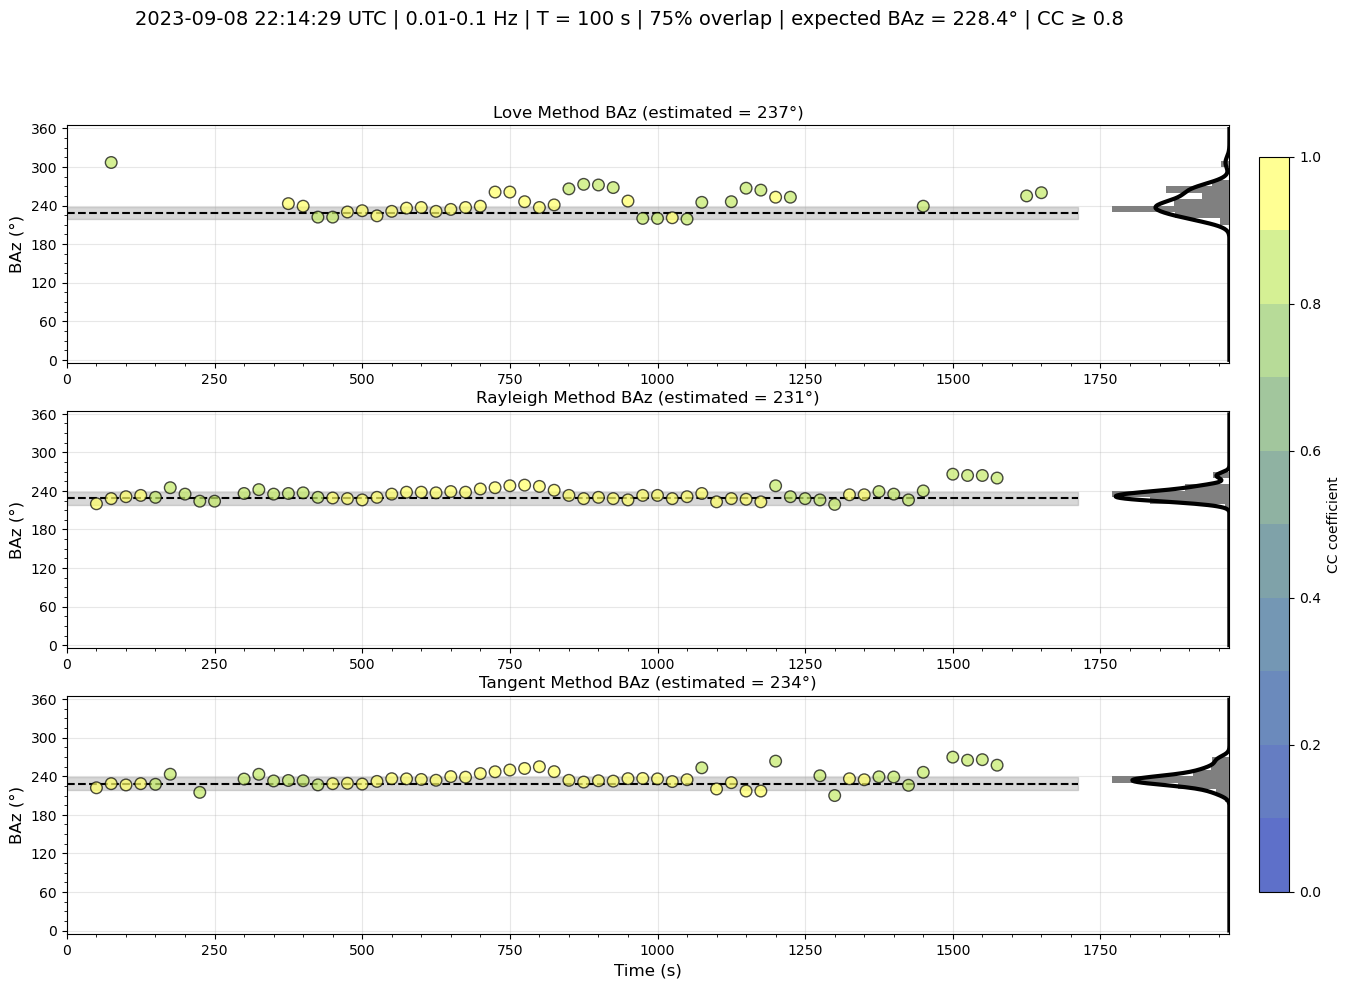

In [22]:
fig, _results = sd.compare_backazimuth_methods(
    Twin=config['twin_sec'],
    Toverlap=config['twin_overlap'],
    cc_threshold=config['cc_threshold'],
    baz_theo=ev['backazimuth'],
    cc_method='mid',
    plot=True,
    output=True
)

if save_figures:
    fig.savefig(f"{config['path_to_figures']}{date}_backazimuth_comparison_mid.png", dpi=150, bbox_inches='tight')

Show backazimuth estimates for the event on a map

In [23]:
results_map = sd.compute_backazimuth_map(
    wave_types=['love', 'rayleigh','tangent'],
    baz_win_sec=config['twin_sec'],
    baz_win_overlap=config['twin_overlap'],
    cc_threshold=config['cc_threshold'],
)

Using precomputed love backazimuth results
Using precomputed rayleigh backazimuth results
Using precomputed tangent backazimuth results


ERROR plotting theoretical great circle: Format specifier missing precision


/home/andbro/Downloads/SixDegreesOfFreedom/src/sixdegrees/plots/plot_backazimuth_map.py:619: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


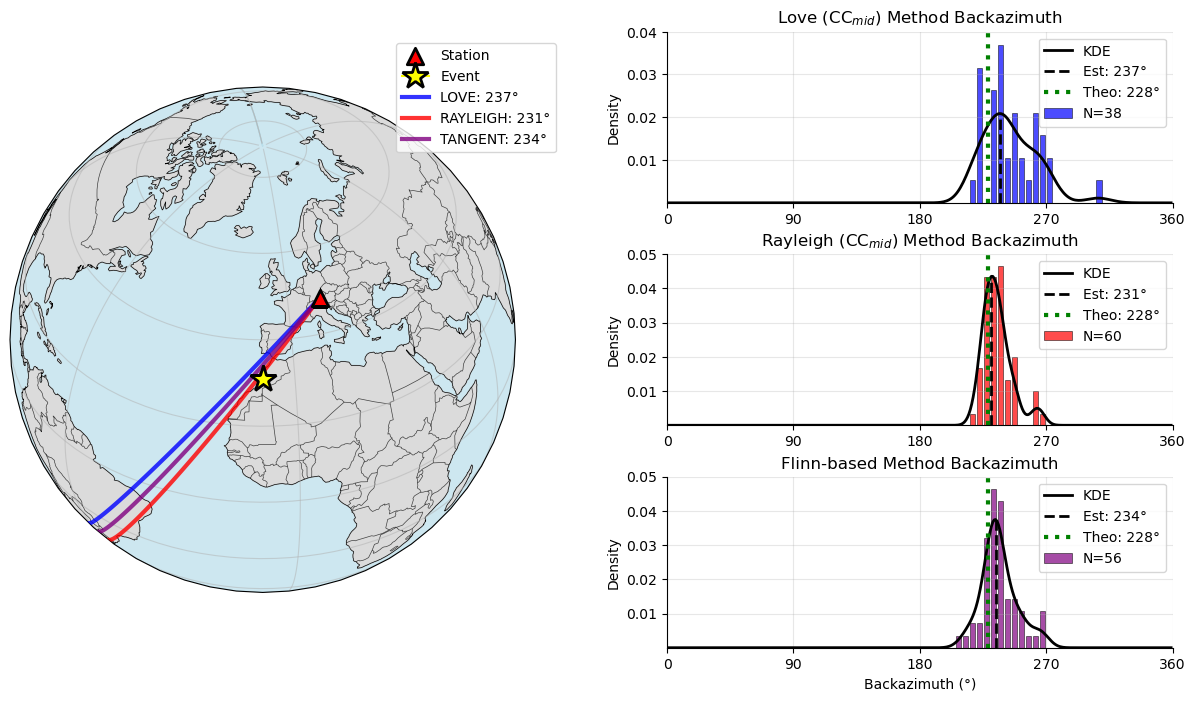

In [24]:
fig = plot_backazimuth_map(
    results_map,
    event_info=ev,
    map_projection='orthographic',  # 'orthographic' or 'platecarree'
)

if fig._suptitle is not None:
    fig._suptitle.remove()

fig.axes[1].set_title(r"Love (CC$_{mid}$) Method Backazimuth")
fig.axes[2].set_title(r"Rayleigh (CC$_{mid}$) Method Backazimuth")
fig.axes[3].set_title(r"Flinn-based Method Backazimuth")


if save_figures:
    fig.savefig(f"{config['path_to_figures']}{date}_backazimuth_map.png", dpi=150, bbox_inches='tight')

### Analyse phase velocities

In [25]:
# Compute Love wave velocities
love_velocities = sd.compute_velocities(
    wave_type='love',
    win_time_s=config['twin_sec'],
    overlap=config['twin_overlap'],
    cc_threshold=config['cc_threshold'],
    method='odr',  # 'odr' | 'ransac'
    # baz=ev['backazimuth']  # theoretical backazimuth (optional)
)

# Compute Rayleigh wave velocities
rayleigh_velocities = sd.compute_velocities(
    wave_type='rayleigh',
    win_time_s=config['twin_sec'],
    overlap=config['twin_overlap'],
    cc_threshold=config['cc_threshold'],
    method='odr',  # 'odr' | 'ransac'
    # baz=ev['backazimuth']  # theoretical backazimuth (optional)
)

Using event BAZ 228.4
Using event BAZ 228.4


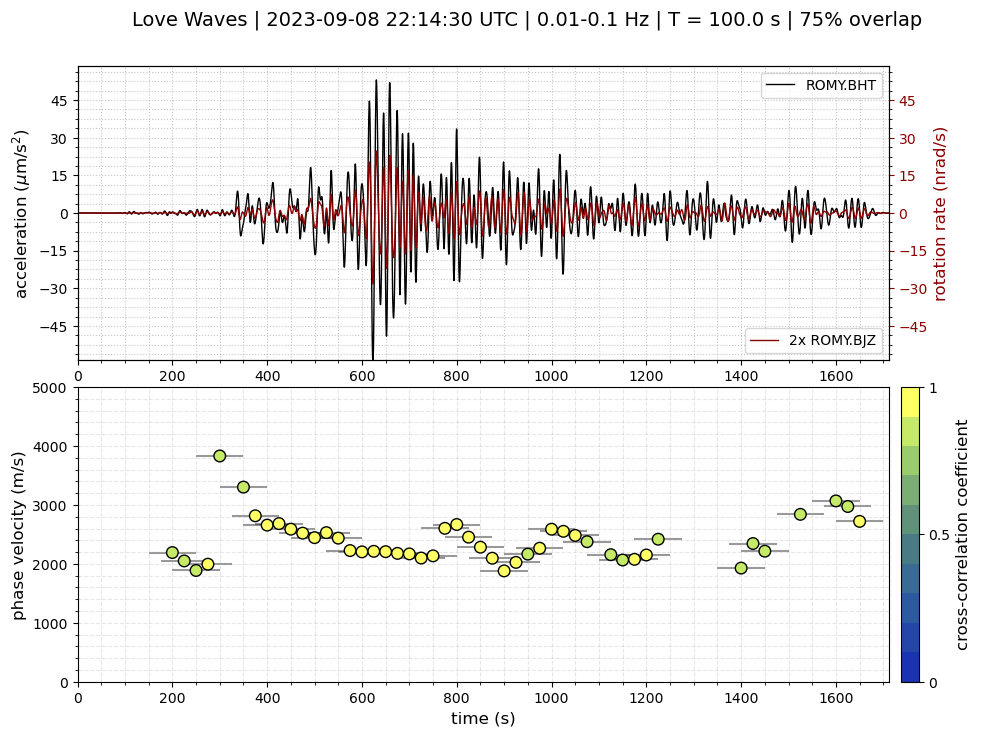

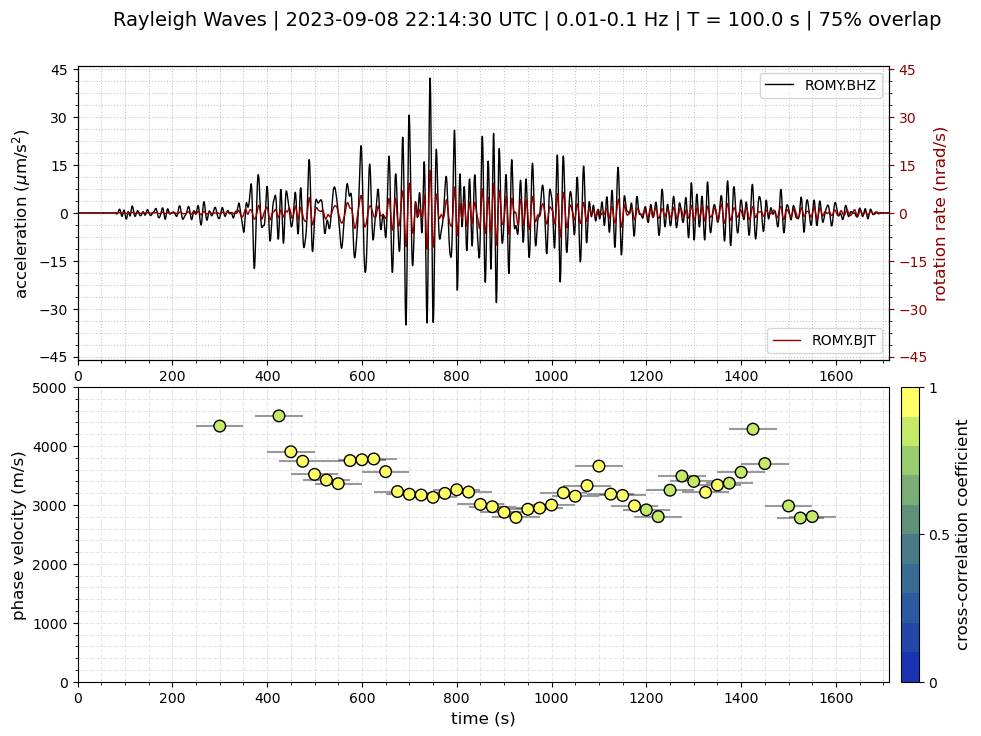

In [26]:
# Plot results
fig = plot_velocities(sd,
    velocity_results=love_velocities,
    vmax=5000,  # optional
    minors=True # optional
)

if save_figures:
    fig.savefig(f"{config['path_to_figures']}{date}_velocities_love.png")

# Plot results
fig = plot_velocities(sd,
    velocity_results=rayleigh_velocities,
    vmax=5000,  # optional
    minors=True # optional
)

if save_figures:
    fig.savefig(f"{config['path_to_figures']}{date}_velocities_rayleigh.png")

### Get Dispersion Plots

In [27]:
params = {
    'fmin': 0.02,
    'fmax': 0.1, # 0.5,
    'octave_fraction': 3,
    'window_factor': 6.0,
    'cc_threshold': 0.8,
    'cc_method': 'mid',
    'baz_step': 1,
    'time_window_overlap': 0.5,
    'regression_method': 'odr', # odr or ransac or theilsen
    'zero_intercept': False, # True
}

In [28]:
# Compute dispersion curve for Love waves
love_results_disp = sd.compute_dispersion_curve(
    wave_type="love",
    fmin=params['fmin'],              # Minimum frequency in Hz
    fmax=params['fmax'],               # Maximum frequency in Hz
    octave_fraction=params['octave_fraction'],      # 1/3 octave bands
    window_factor=params['window_factor'],      # Time window = window_factor / fc
    cc_threshold=params['cc_threshold'],       # Cross-correlation threshold
    cc_method=params['cc_method'],           # Cross-correlation method: 'mid' or 'max'
    time_window_overlap=params['time_window_overlap'],    # Backazimuth window overlap
    velocity_method=params['regression_method'],  # Regression method: 'odr', 'ransac', etc.
    zero_intercept=params['zero_intercept'],    # Force zero intercept
    verbose=False,            # Print progress
    n_jobs=3            # Number of parallel jobs
)



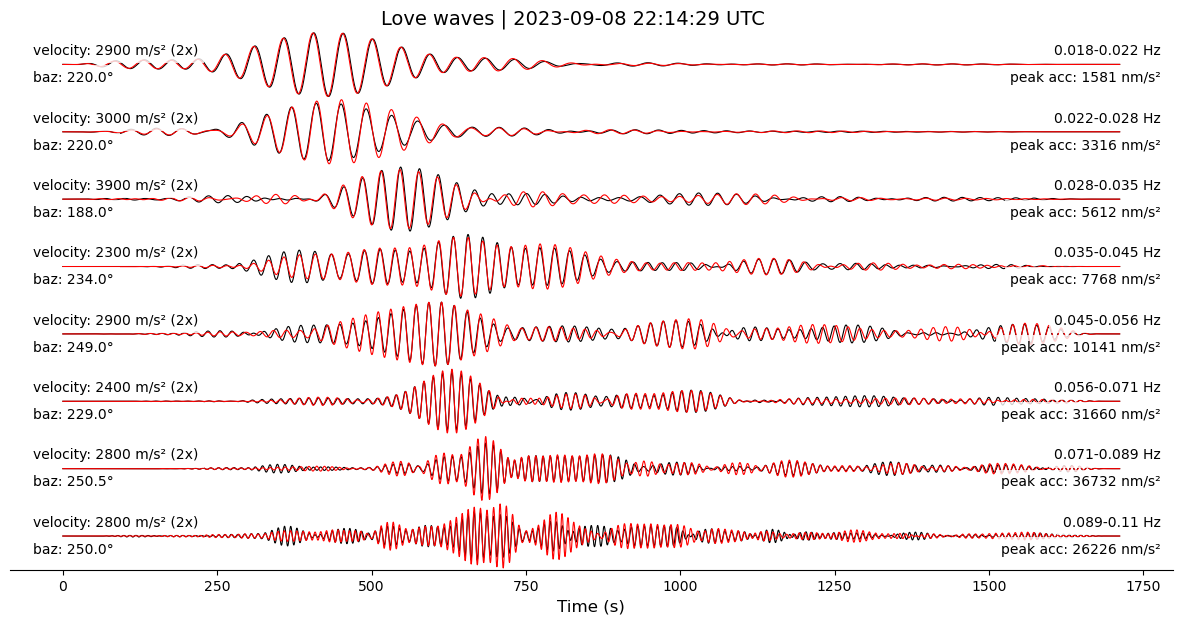

In [ ]:

fig_traces_love = plot_dispersion_traces(
    dispersion_results=love_results_disp,
    unitscale="nano",
    data_type="acceleration",
    figsize=(15, 7),
    show_errors=False,
    velocity_stat='kde_peak'
)

if save_figures:
    fig_traces_love.savefig(f"{config['path_to_figures']}{date}_dispersion_love_{params['cc_method']}.png", dpi=200, bbox_inches='tight')


In [30]:
# Compute dispersion curve for Love waves
rayleigh_results_disp = sd.compute_dispersion_curve(
    wave_type="rayleigh",
    fmin=params['fmin'],              # Minimum frequency in Hz
    fmax=params['fmax'],               # Maximum frequency in Hz
    octave_fraction=params['octave_fraction'],      # 1/3 octave bands
    window_factor=params['window_factor'],      # Time window = window_factor / fc
    cc_threshold=params['cc_threshold'],       # Cross-correlation threshold
    cc_method=params['cc_method'],           # Cross-correlation method: 'mid' or 'max'
    time_window_overlap=params['time_window_overlap'],    # Backazimuth window overlap
    velocity_method=params['regression_method'],  # Regression method: 'odr', 'ransac', etc.
    zero_intercept=params['zero_intercept'],    # Force zero intercept
    verbose=False,            # Print progress
    n_jobs=3            # Number of parallel jobs
)


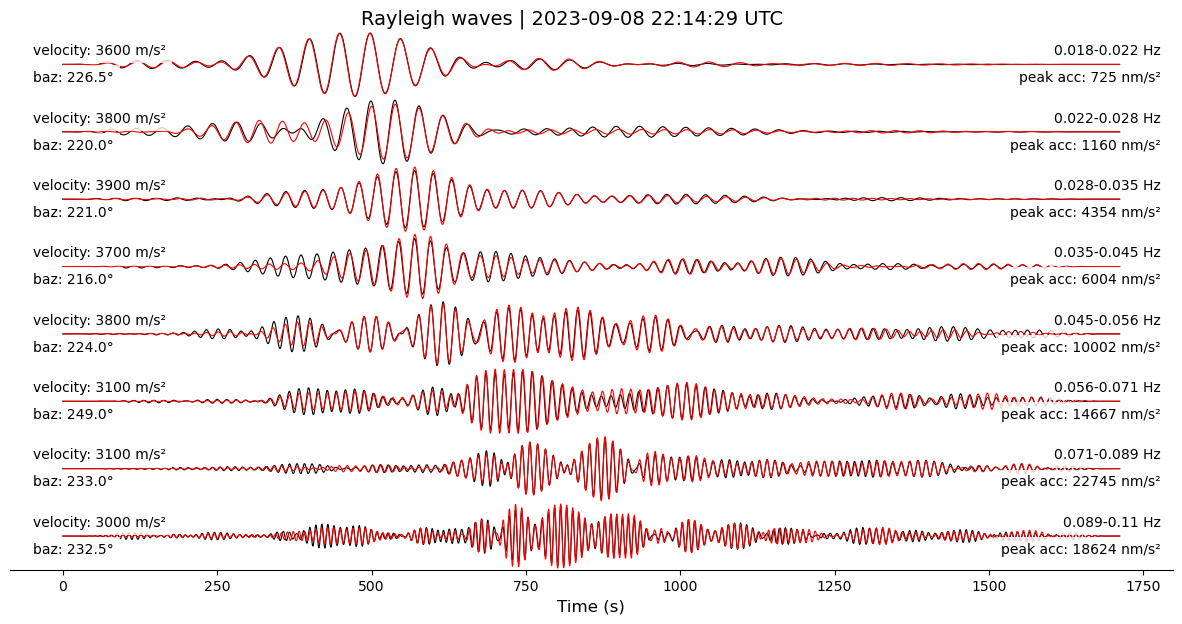

In [ ]:

fig_traces_rayleigh = plot_dispersion_traces(
    dispersion_results=rayleigh_results_disp,
    unitscale="nano",
    data_type="acceleration",
    figsize=(15, 7),
    show_errors=False,
    velocity_stat='kde_peak'
)

if save_figures:
    fig_traces_rayleigh.savefig(f"{config['path_to_figures']}{date}_dispersion_rayleigh_{params['cc_method']}.png", dpi=200, bbox_inches='tight')

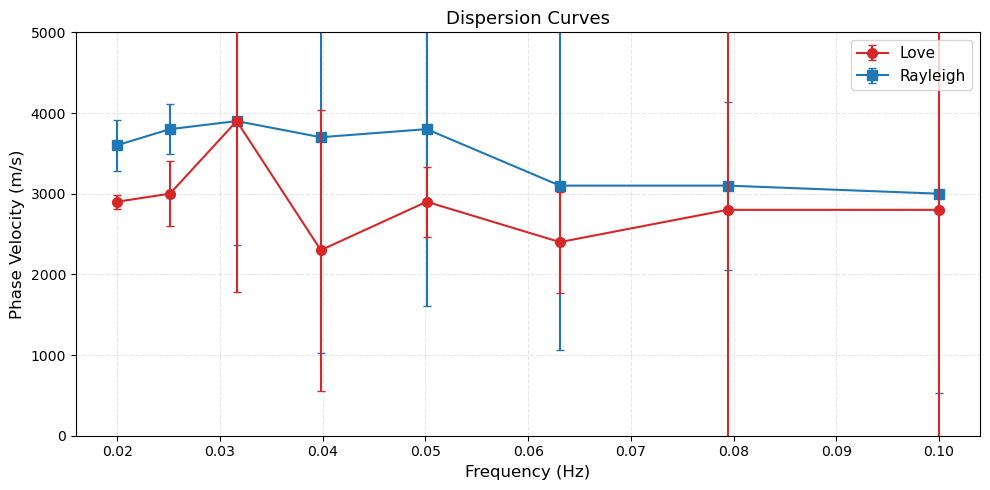

In [32]:
fig_curves = plot_dispersion_curves(
    love_results=love_results_disp,
    rayleigh_results=rayleigh_results_disp,
    figsize=(10, 5),
    xlog=False,                 # Logarithmic x-axis
    ylog=False,                 # Logarithmic y-axis
    markersize=7,
    linewidth=1.5,
    velocity_stat='kde_peak',
    title="Dispersion Curves",  # Optional
    show_errors=True            # Show error bars from KDE deviations
)

if save_figures:
    fig_curves.savefig(f"{config['path_to_figures']}{date}_dispersion_curves_median.png", dpi=200, bbox_inches="tight")


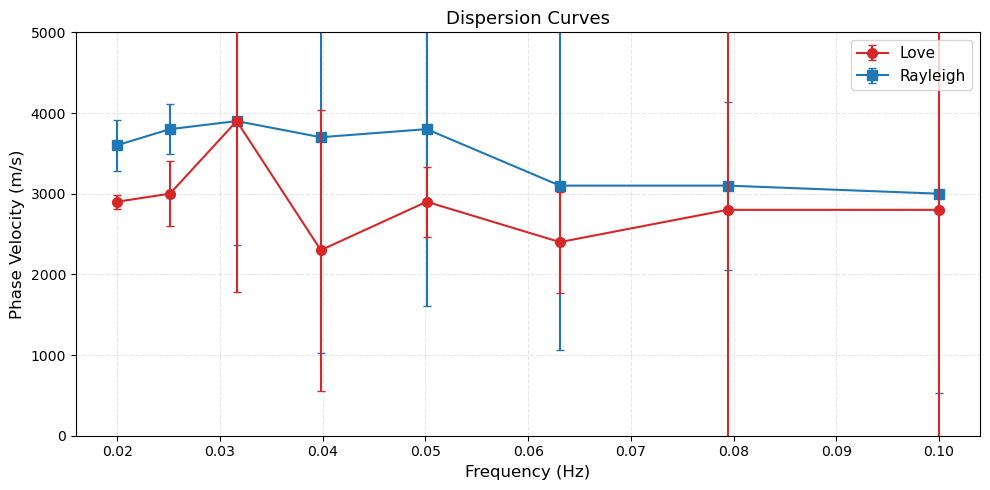

In [33]:
fig_curves = plot_dispersion_curves(
    love_results=love_results_disp,
    rayleigh_results=rayleigh_results_disp,
    figsize=(10, 5),
    xlog=False,                 # Logarithmic x-axis
    ylog=False,                 # Logarithmic y-axis
    markersize=7,
    linewidth=1.5,
    velocity_stat='kde_peak',
    title="Dispersion Curves",  # Optional
    show_errors=True            # Show error bars from KDE deviations
)

if save_figures:
    fig_curves.savefig(f"{config['path_to_figures']}{date}_dispersion_curves_kdepeak.png", dpi=200, bbox_inches="tight")


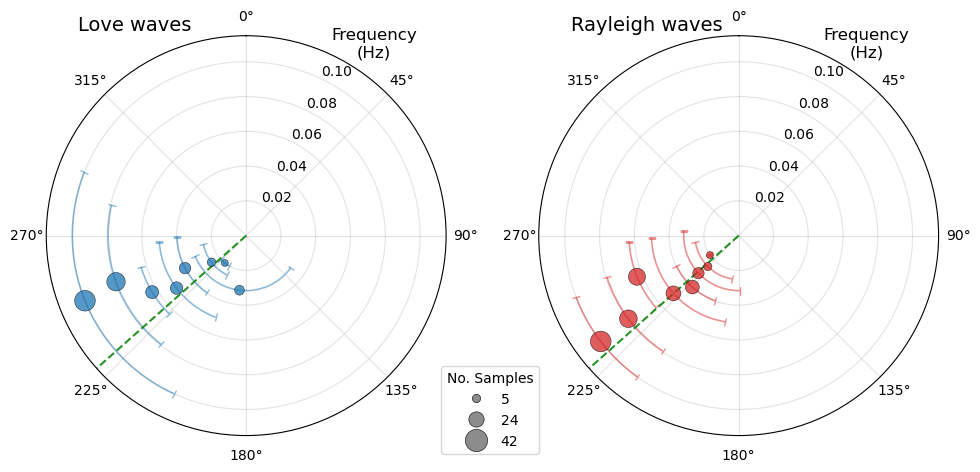

In [34]:
plt.figure(figsize=(10, 5))

from matplotlib.lines import Line2D

S_MIN, S_MAX = 25, 220
LEGEND_MS_MIN, LEGEND_MS_MAX = 6, 16


def _band_baz_and_count(band):
    """
    Per-band backazimuth and count for polar plot.

    - baz: median backazimuth of windows with valid velocity (post CC threshold)
    - baz_std: std of those backazimuths (angular error bar)
    - n_count: n_valid_regressions
    """
    fc = band.get("f_center")
    if fc is None:
        return None

    velocities = np.asarray(band.get("velocities", []), dtype=float)
    backazimuths = np.asarray(band.get("backazimuths", []), dtype=float)
    valid = np.isfinite(velocities)

    n_count = band.get("n_valid_regressions", int(np.sum(valid)))
    if not np.isfinite(n_count):
        n_count = int(np.sum(valid))

    baz_std = np.nan
    if len(backazimuths) == len(velocities) and np.any(valid):
        baz_valid = backazimuths[valid]
        baz = float(np.nanmedian(baz_valid))
        if baz_valid.size > 1:
            baz_std = float(np.nanstd(baz_valid, ddof=0))
        else:
            baz_std = 0.0
    else:
        baz = band.get("baz_used")
        baz = float(baz) if baz is not None and np.isfinite(baz) else np.nan

    if not np.isfinite(baz) or n_count <= 0:
        return None
    return float(fc), baz, float(n_count), float(baz_std) if np.isfinite(baz_std) else 0.0


def _baz_freq_from_dispersion(dispersion_results):
    """Collect filtered baz, std, f_center, n_valid_regressions per band."""
    baz_deg, baz_std_deg, freq_hz, n_counts = [], [], [], []
    for band in dispersion_results.get("frequency_bands", []):
        row = _band_baz_and_count(band)
        if row is None:
            continue
        fc, baz, n_count, baz_std = row
        baz_deg.append(baz)
        baz_std_deg.append(baz_std)
        freq_hz.append(fc)
        n_counts.append(n_count)
    return (
        np.asarray(baz_deg),
        np.asarray(baz_std_deg),
        np.asarray(freq_hz),
        np.asarray(n_counts),
    )


def _scatter_marker_sizes(n_counts, s_min=S_MIN, s_max=S_MAX):
    """Scatter marker area (pt^2), normalized within each panel."""
    sizes = np.full(n_counts.shape, s_min, dtype=float)
    valid = np.isfinite(n_counts) & (n_counts > 0)
    if not valid.any():
        return sizes
    ns = n_counts[valid]
    ns_norm = (ns - ns.min()) / (ns.max() - ns.min() + 1e-9)
    sizes[valid] = s_min + ns_norm * (s_max - s_min)
    return sizes


def _legend_markersize(n, n_lo, n_hi, ms_min=LEGEND_MS_MIN, ms_max=LEGEND_MS_MAX):
    """Legend marker size (pt) scaled to regression count."""
    if np.isclose(n_lo, n_hi):
        return 0.5 * (ms_min + ms_max)
    frac = (n - n_lo) / (n_hi - n_lo)
    return ms_min + frac * (ms_max - ms_min)


wave_panels = [
    (love_results_disp, "Love", "tab:blue"),
    (rayleigh_results_disp, "Rayleigh", "tab:red"),
]

panel_data = [
    (title, color, *_baz_freq_from_dispersion(results))
    for results, title, color in wave_panels
]

all_freq = [freq_hz for _, _, _, freq_hz, _, _ in panel_data if freq_hz.size]
r_max = float(np.max(np.concatenate(all_freq))) if all_freq else 1.0
r_max *= 1.05

for i, (title, color, baz_deg, baz_std_deg, freq_hz, n_counts) in enumerate(panel_data, start=1):
    ax = plt.subplot(1, 2, i, projection="polar")

    if baz_deg.size:
        theta = np.deg2rad(baz_deg)
        theta_err = np.deg2rad(np.where(np.isfinite(baz_std_deg), baz_std_deg, 0.0))

        ax.errorbar(
            theta,
            freq_hz,
            xerr=theta_err,
            fmt="none",
            ecolor=color,
            elinewidth=1.2,
            capsize=3,
            capthick=1.0,
            alpha=0.5,
            zorder=2,
        )
        ax.scatter(
            theta,
            freq_hz,
            s=_scatter_marker_sizes(n_counts),
            c=color,
            alpha=0.75,
            edgecolors="k",
            linewidths=0.4,
            zorder=3,
        )

    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_ylim(0, config['fmax']*1.15)
    ax.grid(True, alpha=0.35)

    ax.text(0.08, 1.05, title + " waves", transform=ax.transAxes, fontsize=14, va="top")

    ax.set_rlabel_position(25.5)
    ax.text(0.82, 0.98, "Frequency\n(Hz)", transform=ax.transAxes, fontsize=12, ha="center", va="center")

    if ev.get("backazimuth") is not None:
        ax.axvline(
            np.deg2rad(ev["backazimuth"]),
            color="green",
            ls="--",
            lw=1.5,
            alpha=0.85,
            label="Theoretical BAZ",
        )

# Size legend: n_valid_regressions (CC-filtered windows per band)
fig = plt.gcf()
all_n_counts = np.concatenate([
    n_counts[np.isfinite(n_counts) & (n_counts > 0)]
    for _, _, _, _, _, n_counts in panel_data
    if n_counts.size
]) if panel_data else np.array([])

if all_n_counts.size:
    n_lo, n_hi = float(all_n_counts.min()), float(all_n_counts.max())
    legend_values = [n_lo, n_hi] if np.isclose(n_lo, n_hi) else [n_lo, 0.5 * (n_lo + n_hi), n_hi]

    size_handles = []
    size_labels = []
    for n in legend_values:
        size_handles.append(
            Line2D(
                [], [],
                linestyle="None",
                marker="o",
                markersize=_legend_markersize(n, n_lo, n_hi),
                markerfacecolor="0.55",
                markeredgecolor="k",
                markeredgewidth=0.4,
            )
        )
        size_labels.append(f"{int(round(n))}")

    fig.legend(
        size_handles,
        size_labels,
        title="No. Samples",
        loc="lower center",
        bbox_to_anchor=(0.5, 0.1),
        ncol=1,
        frameon=True,
        fontsize=10,
        title_fontsize=10,
        handletextpad=0.8,
    )

plt.tight_layout(rect=[0, 0.10, 1, 1])

if save_figures:
    plt.savefig(
        f"{config['path_to_figures']}{date}_dispersion_baz_freq_polar.png",
        dpi=200,
        bbox_inches="tight",
    )

plt.show()


## Get Full Event Analysis

In [35]:
from sixdegrees.plots.plot_event_overview import plot_event_overview

Theoretical P-arrival: 2023-09-08T22:16:02.016641Z
Theoretical S-arrival: 2023-09-08T22:20:10.994445Z


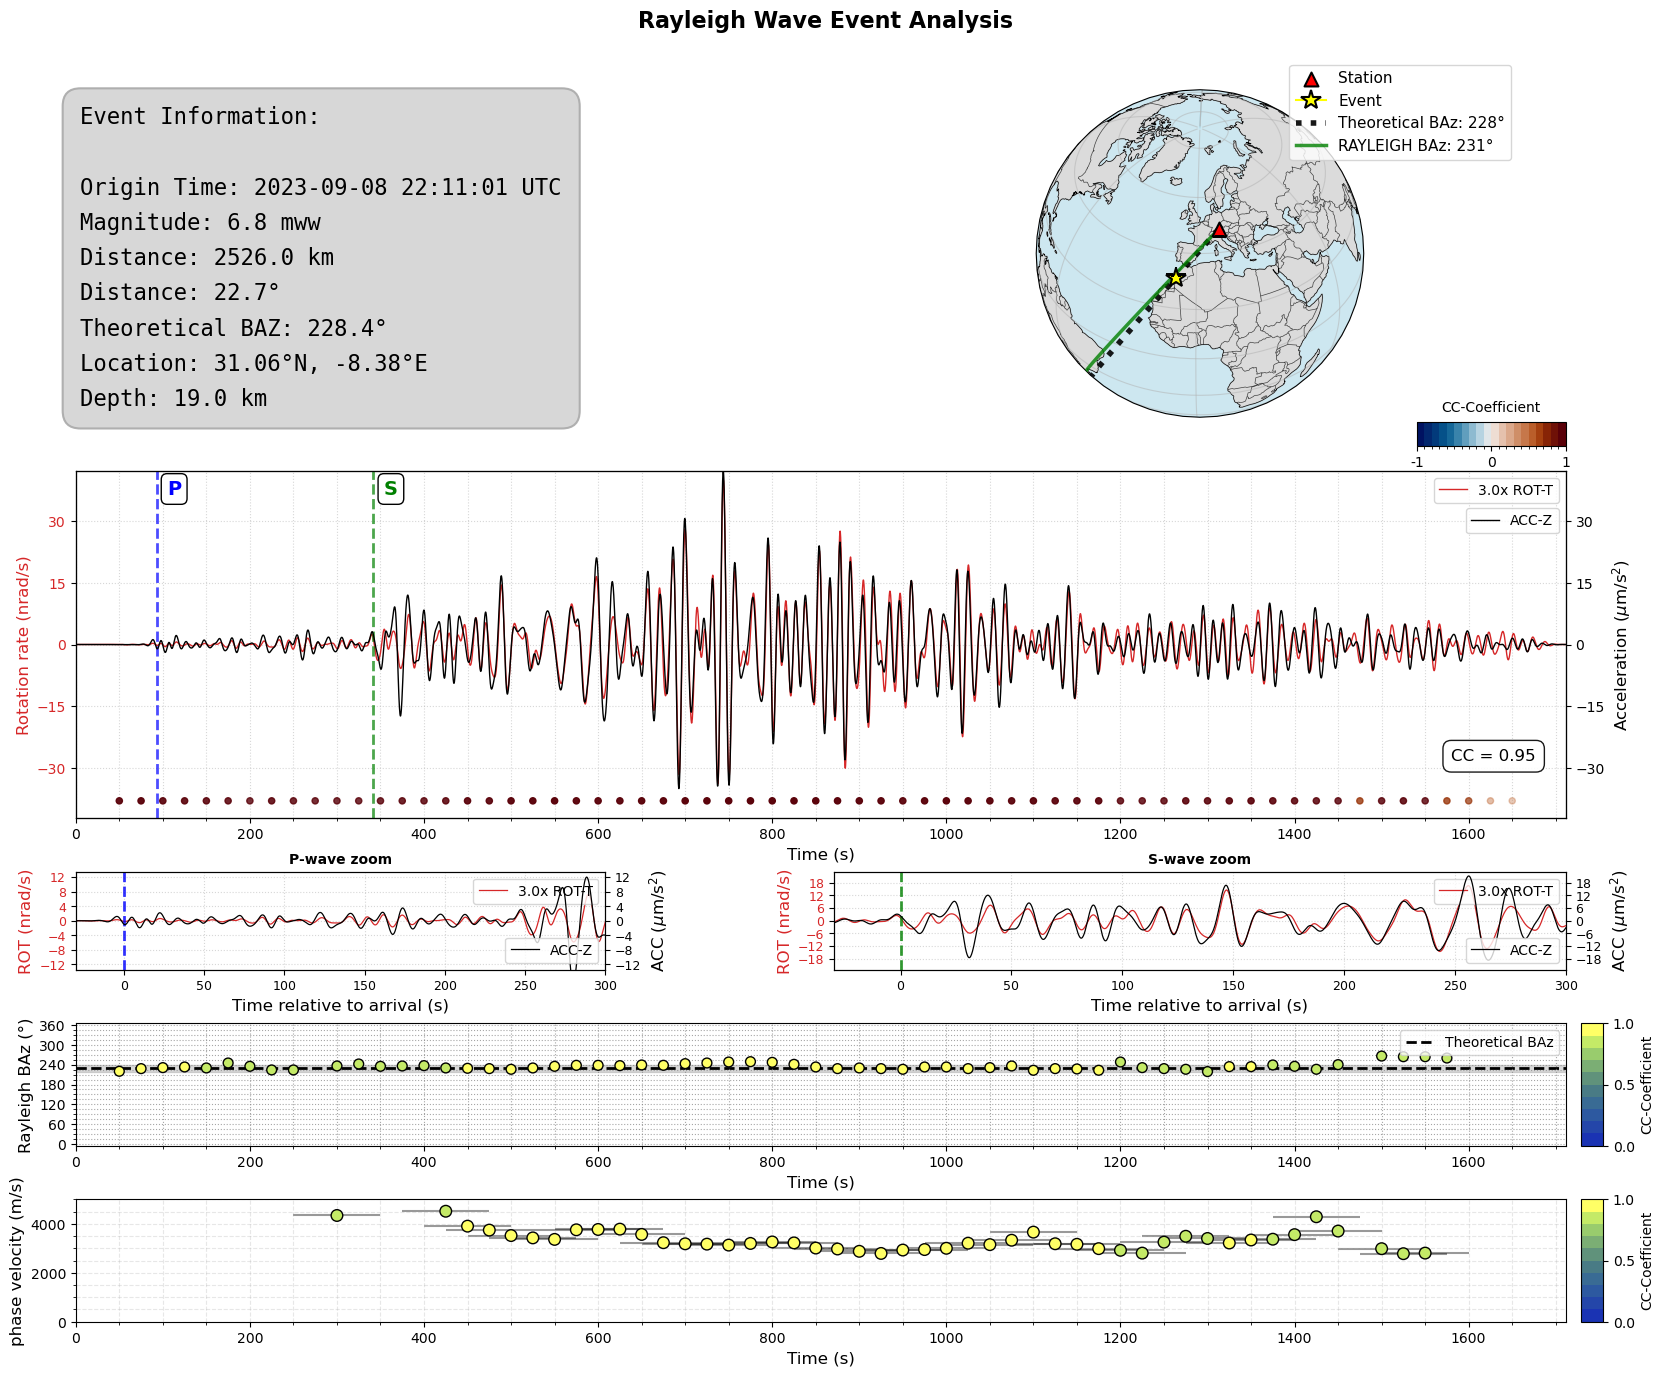

In [36]:
fig = plot_event_overview(sd, 
    baz_results_rayleigh,
    rayleigh_velocities,
    event_info=ev,
    wave_type='rayleigh',
    baz_theo=ev['backazimuth'],
    cc_threshold=config['cc_threshold'],
    vmax=5000,
    cc_method='mid',
    twin_sec=config['twin_sec'],
    twin_overlap=config['twin_overlap'],
    zoom_t1=30,
    zoom_t2=300
)

if save_figures:
    fig.savefig(f"{config['path_to_figures']}{date}_event_overview_rayleigh_mid.png")

Theoretical P-arrival: 2023-09-08T22:16:02.016641Z
Theoretical S-arrival: 2023-09-08T22:20:10.994445Z


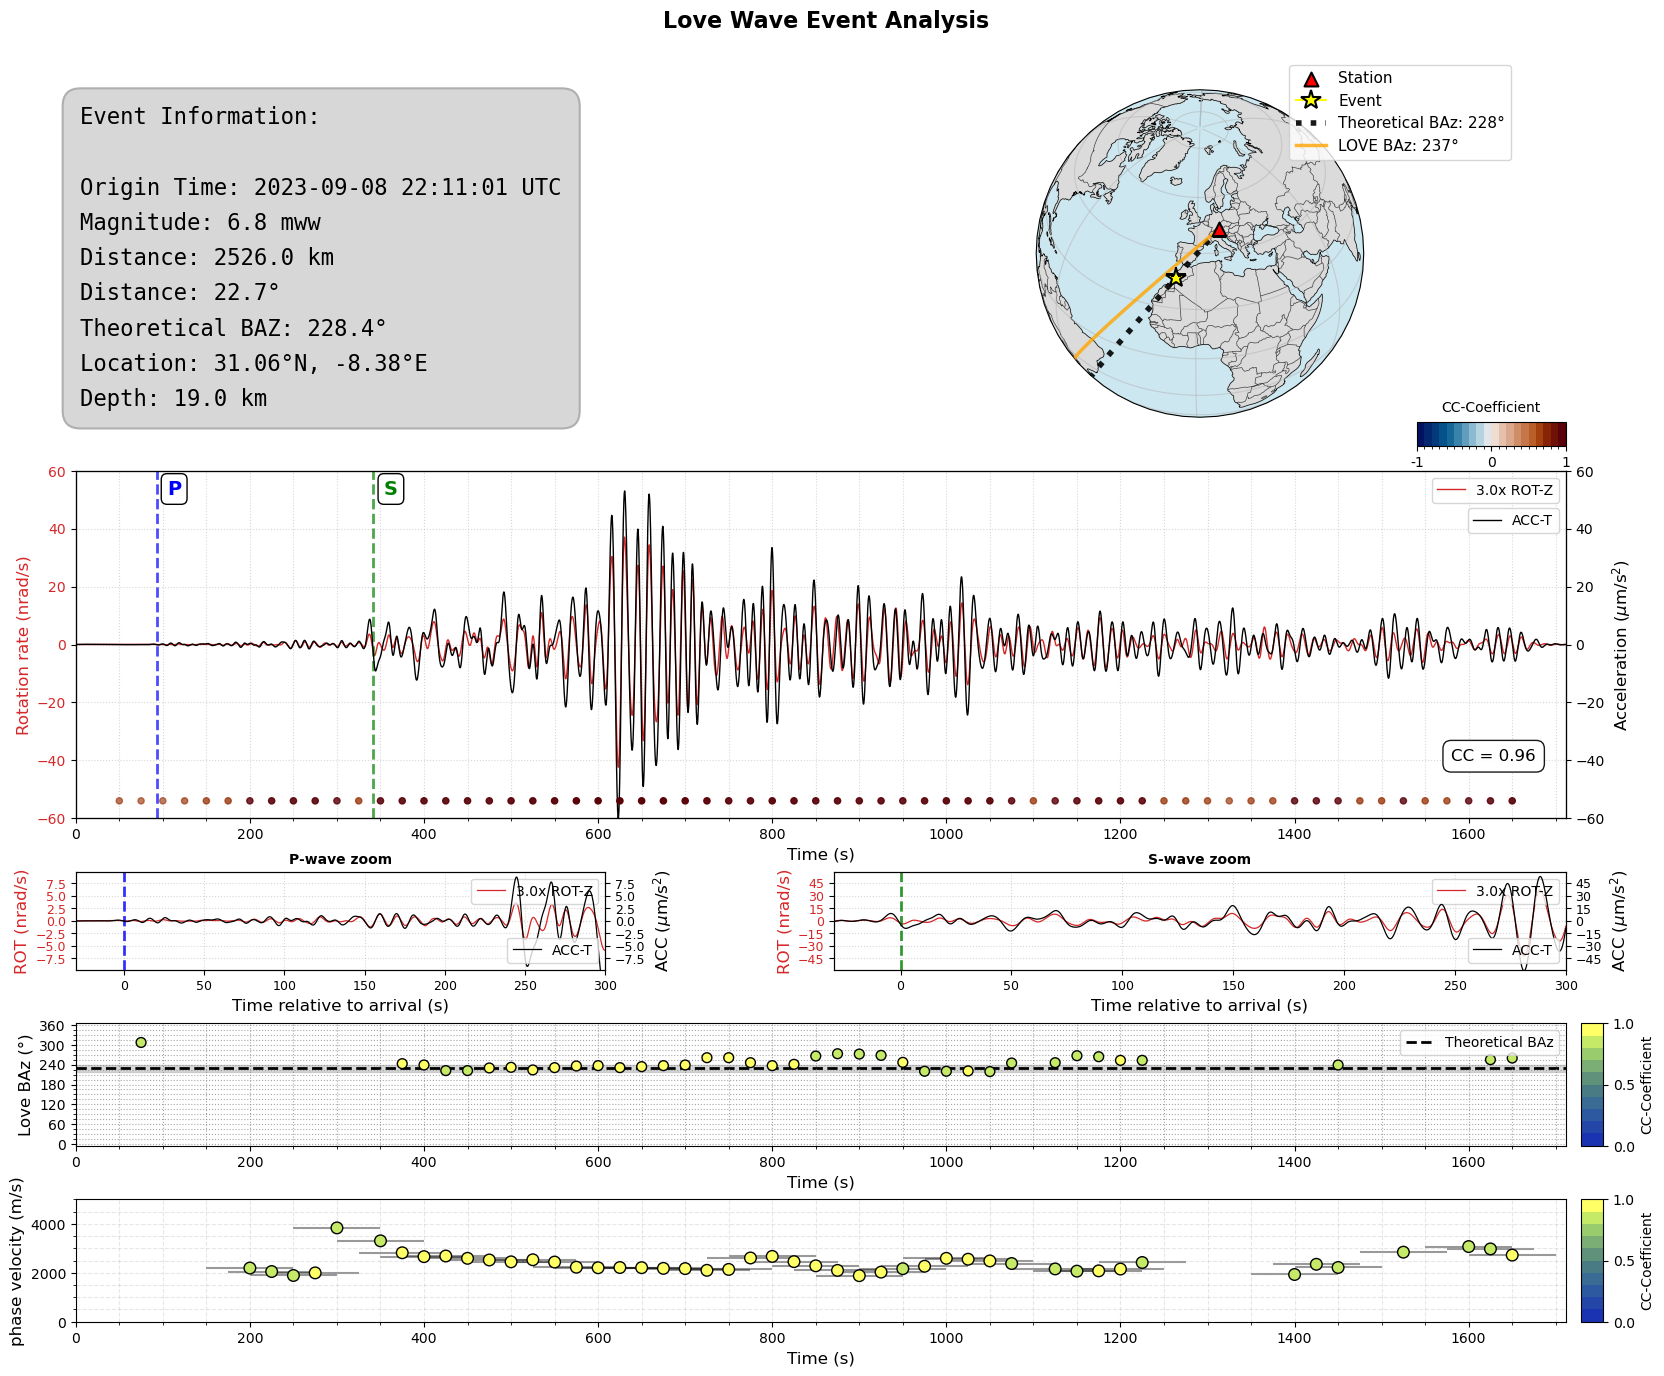

In [37]:
fig = plot_event_overview(sd, 
    baz_results_love,
    love_velocities,
    event_info=ev,
    wave_type='love',
    baz_theo=ev['backazimuth'],
    cc_threshold=config['cc_threshold'],
    vmax=5000,
    cc_method='mid',
    twin_sec=config['twin_sec'],
    twin_overlap=config['twin_overlap'],
    zoom_t1=30,
    zoom_t2=300
)

if save_figures:
    fig.savefig(f"{config['path_to_figures']}{date}_event_overview_love_mid.png")